In [9]:
!pip install yfinance numpy pandas matplotlib seaborn scipy

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from scipy.optimize import minimize

plt.style.use('seaborn-v0_8')

In [11]:
ativos = ['PETR4.SA', 'VALE3.SA', 'ITUB4.SA']  # <- troque aqui
start = '2020-01-01'
end = '2025-01-01'

In [13]:
data = yf.download(ativos, start=start, end=end, auto_adjust=True)
precos = data['Close']
retornos = precos.pct_change().dropna()

[*********************100%***********************]  3 of 3 completed


In [14]:
retorno_medio = retornos.mean() * 252
cov_matrix = retornos.cov() * 252

print("Retorno anual esperado:\n", retorno_medio)
print("\nMatriz de covariância:\n", cov_matrix)

Retorno anual esperado:
 Ticker
ITUB4.SA    0.055541
PETR4.SA    0.367243
VALE3.SA    0.164934
dtype: float64

Matriz de covariância:
 Ticker    ITUB4.SA  PETR4.SA  VALE3.SA
Ticker                                
ITUB4.SA  0.102647  0.072250  0.043998
PETR4.SA  0.072250  0.198843  0.078845
VALE3.SA  0.043998  0.078845  0.141069


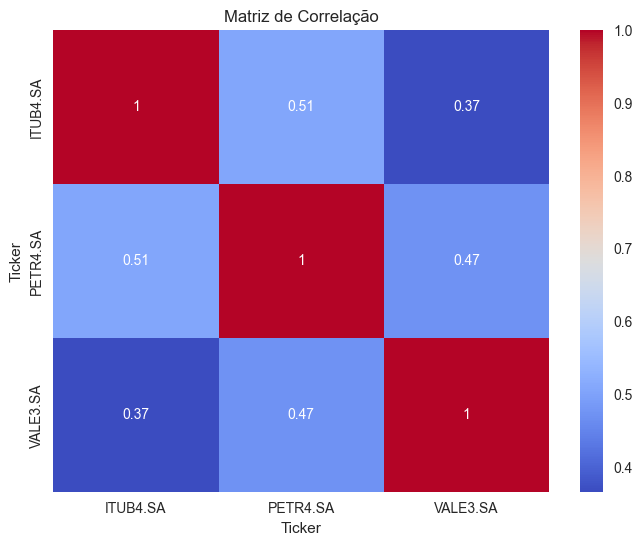

In [15]:
plt.figure(figsize=(8,6))
sns.heatmap(retornos.corr(), annot=True, cmap='coolwarm')
plt.title("Matriz de Correlação")
plt.show()

In [16]:
def portfolio_performance(weights, mean_returns, cov_matrix):
    returns = np.dot(weights, mean_returns)
    volatility = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))
    return returns, volatility

def neg_sharpe_ratio(weights, mean_returns, cov_matrix, risk_free_rate=0.05):
    p_ret, p_vol = portfolio_performance(weights, mean_returns, cov_matrix)
    return -(p_ret - risk_free_rate) / p_vol

In [17]:
num_assets = len(ativos)
args = (retorno_medio, cov_matrix)

constraints = ({'type': 'eq', 'fun': lambda x: np.sum(x) - 1})
bounds = tuple((0,1) for _ in range(num_assets))

init_guess = num_assets * [1./num_assets]

resultado = minimize(neg_sharpe_ratio, init_guess,
                     args=args,
                     method='SLSQP',
                     bounds=bounds,
                     constraints=constraints)

pesos_otimos = resultado.x

In [18]:
ret_otimo, vol_otimo = portfolio_performance(pesos_otimos, retorno_medio, cov_matrix)

print("Pesos ótimos:")
for i, ativo in enumerate(ativos):
    print(f"{ativo}: {pesos_otimos[i]:.2%}")

print(f"\nRetorno esperado: {ret_otimo:.2%}")
print(f"Volatilidade: {vol_otimo:.2%}")
print(f"Sharpe: {(ret_otimo-0.05)/vol_otimo:.2f}")

Pesos ótimos:
PETR4.SA: 0.00%
VALE3.SA: 100.00%
ITUB4.SA: 0.00%

Retorno esperado: 36.72%
Volatilidade: 44.59%
Sharpe: 0.71


In [19]:
num_portfolios = 5000

results = np.zeros((3, num_portfolios))
weights_record = []

for i in range(num_portfolios):
    weights = np.random.random(num_assets)
    weights /= np.sum(weights)
    
    ret, vol = portfolio_performance(weights, retorno_medio, cov_matrix)
    
    results[0,i] = ret
    results[1,i] = vol
    results[2,i] = (ret - 0.05) / vol
    
    weights_record.append(weights)

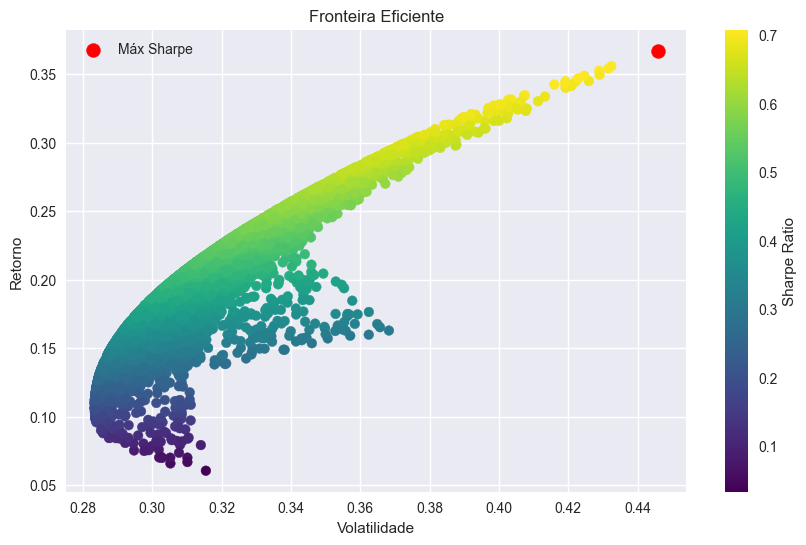

In [20]:
plt.figure(figsize=(10,6))
plt.scatter(results[1,:], results[0,:], c=results[2,:], cmap='viridis')

plt.colorbar(label='Sharpe Ratio')
plt.scatter(vol_otimo, ret_otimo, color='red', s=100, label='Máx Sharpe')

plt.xlabel('Volatilidade')
plt.ylabel('Retorno')
plt.title('Fronteira Eficiente')
plt.legend()
plt.show()